# Clean data into final model-ready data set

In [6]:
import pandas as pd

# Load engineered dataset
df = pd.read_csv('../data/merged_tracking_injury_features.csv')

# Basic descriptive stats
print(df[['minutes_float', 'distance', 'speed', 'load_intensity']].describe())

# Injury counts
print(df['injury'].value_counts())
print(df['injury_type'].value_counts())

       minutes_float      distance         speed  load_intensity
count   25765.000000  25765.000000  25765.000000    25765.000000
mean       26.837129      1.986304      4.173330        0.312601
std         9.348182      0.675488      0.264604        0.042326
min         0.033333      0.010000      2.190000        0.000814
25%        20.700000      1.560000      4.000000        0.286708
50%        28.466667      2.100000      4.170000        0.311117
75%        34.133333      2.500000      4.340000        0.336242
max        52.733333      3.820000      7.140000        2.007000
injury
0    25457
1      308
Name: count, dtype: int64
injury_type
Ankle        117
Knee         106
Hamstring     41
Calf          31
Achilles      13
Name: count, dtype: int64


In [16]:
import pandas as pd
import numpy as np

# -----------------------------
# 0️⃣ Load your data
# -----------------------------
# df = pd.read_csv('data/model_ready_data.csv')

# -----------------------------
# 1️⃣ Drop duplicates
# -----------------------------
df = df.drop_duplicates(subset=['PLAYER_ID', 'GAME_ID'])

# -----------------------------
# 2️⃣ Filter implausible values
# -----------------------------
df = df[df['minutes_float'] >= 1]
df = df[df['speed'] <= 15]     
df = df[df['distance'] <= 10]  

# -----------------------------
# 3️⃣ Handle rolling/lag/acwr/pct_change NaNs
# -----------------------------
rolling_lag_cols = [col for col in df.columns 
                    if 'rolling' in col or 'lag' in col or 'acwr' in col or 'pct_change' in col]

for col in rolling_lag_cols:
    if 'acwr' in col:
        df[col] = df[col].replace([np.inf, -np.inf], 1).fillna(1)
    elif 'pct_change' in col:
        df[col] = df[col].replace([np.inf, -np.inf], 0).fillna(0)
    else:
        df[col] = df[col].replace([np.inf, -np.inf], 0).fillna(0)

# -----------------------------
# 4️⃣ Handle other numeric columns
# -----------------------------
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols] = df[numeric_cols].replace([np.inf, -np.inf], np.nan)  # turn inf into NaN
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())    # median imputation

# -----------------------------
# 5️⃣ Encode categorical features
# -----------------------------
df['home_game'] = df['MATCHUP'].apply(lambda x: 0 if '@' in x else 1)

# -----------------------------
# 6️⃣ Winsorize extreme z-scores
# -----------------------------
z_cols = ['distance_z', 'speed_z']
for col in z_cols:
    if col in df.columns:
        df[col] = np.clip(df[col], -3, 3)

# -----------------------------
# 7️⃣ Verify cleaning
# -----------------------------
print("Missing values after cleaning:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nAny infinite values left?")
print(np.isinf(df.select_dtypes(include=np.number)).sum())
print("\nSummary statistics after cleaning:")
print(df.describe())

Missing values after cleaning:
injury_type       25415
prev_game_date      166
dtype: int64

Any infinite values left?
SEASON_ID                   0
PLAYER_ID                   0
GAME_ID                     0
MIN                         0
injury                      0
                           ..
prev_3_games_minutes_avg    0
prev_3_games_load_sum       0
rest_days                   0
short_rest                  0
home_game                   0
Length: 68, dtype: int64

Summary statistics after cleaning:
          SEASON_ID     PLAYER_ID       GAME_ID           MIN        injury  \
count  25721.000000  2.572100e+04  2.572100e+04  25721.000000  25721.000000   
mean   22022.924031  1.166177e+06  2.229300e+07     26.885385      0.011897   
std        0.807853  6.695799e+05  8.078324e+04      9.299029      0.108424   
min    22022.000000  2.544000e+03  2.220000e+07      1.000000      0.000000   
25%    22022.000000  2.035520e+05  2.220082e+07     21.000000      0.000000   
50%    22023.000

In [17]:
df['rest_days'] = df['rest_days'].clip(upper=14)

rolling_features = [
    'rolling_distance_3', 'rolling_speed_3', 'rolling_minutes_3',
    'rolling_distance_5', 'rolling_speed_5', 'rolling_minutes_5',
    'rolling_distance_10', 'rolling_speed_10', 'rolling_minutes_10',
    'rolling_distance_20', 'distance_lag1', 'speed_lag1', 'minutes_lag1',
    'distance_lag2', 'speed_lag2', 'minutes_lag2',
    'distance_lag3', 'speed_lag3', 'minutes_lag3',
    'prev_game_minutes', 'prev_game_distance', 'prev_game_speed', 'prev_game_load',
    'prev_3_games_minutes_avg', 'prev_3_games_load_sum'
]

df[rolling_features] = df[rolling_features].fillna(0)

In [18]:
df.to_csv('../data/model_ready_data.csv')

# Logistic Regression

In [51]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

# -----------------------------
# 1️⃣ Prepare features and target
# -----------------------------
# Assume df is your cleaned dataset
target = 'injury'  # binary: 0 = no injury, 1 = injury

# Select numeric features only (drop categorical or identifiers)
drop_cols = ['Unnamed: 0','PLAYER_ID', 'GAME_ID', 'SEASON_ID', 'personId', 'gameId', 'prev_game_date']
X = df.drop(columns=drop_cols + [target])
y = df[target]

# -----------------------------
# 2️⃣ Handle NaNs, inf, extreme values
# -----------------------------

# Keep only numeric columns
X = X.select_dtypes(include=np.number)

# Replace inf/-inf with NaN
X = X.replace([np.inf, -np.inf], np.nan)

# Fill NaNs with median (numeric only)
X = X.fillna(X.median())

# Clip extreme values in z-score/per_min columns
z_cols = [col for col in X.columns if 'z' in col or 'per_min' in col]
for col in z_cols:
    X[col] = X[col].clip(-10, 10)

# -----------------------------
# 3️⃣ Split data
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 4️⃣ Feature scaling
# -----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -----------------------------
# 5️⃣ Train Logistic Regression with class weighting
# -----------------------------
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# -----------------------------
# 6️⃣ Predictions & evaluation
# -----------------------------
y_pred = model.predict(X_test_scaled)
y_proba = model.predict_proba(X_test_scaled)[:, 1]  # probability of injury

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print("\nROC-AUC Score:", roc_auc_score(y_test, y_proba))

# -----------------------------
# 7️⃣ Optional: feature importance
# -----------------------------
feature_importance = pd.Series(model.coef_[0], index=X.columns).sort_values(ascending=False)
print("\nTop 10 features influencing injury risk:")
print(feature_importance.head(10))

Confusion Matrix:
[[3674 1410]
 [  14   47]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.72      0.84      5084
           1       0.03      0.77      0.06        61

    accuracy                           0.72      5145
   macro avg       0.51      0.75      0.45      5145
weighted avg       0.98      0.72      0.83      5145


ROC-AUC Score: 0.8328023629257975

Top 10 features influencing injury risk:
rolling_minutes_5           2.249707
prev_3_games_minutes_avg    1.837723
minutes_float               1.561557
rolling_14d_minutes_avg     1.542012
rolling_distance_3          1.519374
distance_lag3               1.515416
rolling_distance_10         1.383122
distance_lag1               1.349480
distance_lag2               1.225365
speed_lag1                  1.204504
dtype: float64


In [ ]:
# =============================
# Logistic Regression Injury Model
# =============================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score,
    precision_recall_curve
)

# -----------------------------
# 1️⃣ Prepare Features and Target
# -----------------------------
# X: numeric features only, already cleaned (no NaN/inf)
# y: injury target (0=no injury, 1=injury)
# Make sure you already did:
# X = X.replace([np.inf, -np.inf], np.nan)
# X = X.fillna(X.median())

# -----------------------------
# 2️⃣ Train-Test Split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 3️⃣ Feature Scaling
# -----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# -----------------------------
# 4️⃣ Train Logistic Regression
# -----------------------------
# Use class_weight='balanced' for rare injuries
logreg = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
logreg.fit(X_train_scaled, y_train)

# -----------------------------
# 5️⃣ Predicted Probabilities
# -----------------------------
y_probs = logreg.predict_proba(X_test_scaled)[:, 1]

# Optional: adjust threshold for minority class
threshold = 0.05  # can tweak higher/lower based on PR curve
y_pred = (y_probs >= threshold).astype(int)

# -----------------------------
# 6️⃣ Evaluate Model
# -----------------------------
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

cr = classification_report(y_test, y_pred)
print("\nClassification Report:\n", cr)

roc_auc = roc_auc_score(y_test, y_probs)
print("\nROC-AUC Score:", roc_auc)

# -----------------------------
# 7️⃣ Top Features by Absolute Coefficient
# -----------------------------
feature_importance = pd.Series(
    np.abs(logreg.coef_[0]), index=X.columns
).sort_values(ascending=False)
print("\nTop 10 Features Influencing Injury Risk:\n", feature_importance.head(10))

# -----------------------------
# 8️⃣ Optional: Precision-Recall Curve
# -----------------------------
precision, recall, thresholds = precision_recall_curve(y_test, y_probs)

Confusion Matrix:
 [[2131 2953]
 [   0   61]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.42      0.59      5084
           1       0.02      1.00      0.04        61

    accuracy                           0.43      5145
   macro avg       0.51      0.71      0.32      5145
weighted avg       0.99      0.43      0.58      5145


ROC-AUC Score: 0.8328023629257975

Top 10 Features Influencing Injury Risk:
 rolling_14d_distance_avg    2.672005
cumulative_distance         2.558994
rolling_minutes_5           2.249707
minutes_lag3                1.988759
minutes_lag2                1.960912
prev_3_games_load_sum       1.916787
prev_3_games_minutes_avg    1.837723
rolling_distance_5          1.776675
minutes_float               1.561557
prev_game_minutes           1.544727
dtype: float64


In [61]:
# =============================
# Logistic Regression Injury Model (SMOTE + Undersampling)
# =============================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score,
    precision_recall_curve
)

# 🔥 NEW: Resampling tools
from imblearn.combine import SMOTEENN

# -----------------------------
# 1️⃣ Train-Test Split
# -----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 2️⃣ Apply SMOTE + Undersampling (TRAIN ONLY)
# -----------------------------
smote_enn = SMOTEENN(random_state=42)

X_train_resampled, y_train_resampled = smote_enn.fit_resample(X_train, y_train)

print("Before Resampling:", np.bincount(y_train))
print("After Resampling:", np.bincount(y_train_resampled))

# -----------------------------
# 3️⃣ Feature Scaling (AFTER resampling)
# -----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_resampled)
X_test_scaled = scaler.transform(X_test)

# -----------------------------
# 4️⃣ Train Logistic Regression
# -----------------------------
logreg = LogisticRegression(
    class_weight=None,   # ❗ turn OFF since we resampled
    max_iter=1000,
    random_state=42
)

logreg.fit(X_train_scaled, y_train_resampled)

# -----------------------------
# 5️⃣ Predicted Probabilities
# -----------------------------
y_probs = logreg.predict_proba(X_test_scaled)[:, 1]

# Lower threshold for rare events
threshold = 0.05
y_pred = (y_probs >= threshold).astype(int)

# -----------------------------
# 6️⃣ Evaluate Model
# -----------------------------
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)

cr = classification_report(y_test, y_pred)
print("\nClassification Report:\n", cr)

roc_auc = roc_auc_score(y_test, y_probs)
print("\nROC-AUC Score:", roc_auc)

# -----------------------------
# 7️⃣ Feature Importance
# -----------------------------
feature_importance = pd.Series(
    np.abs(logreg.coef_[0]), index=X.columns
).sort_values(ascending=False)

print("\nTop 10 Features Influencing Injury Risk:\n", feature_importance.head(10))

# -----------------------------
# 8️⃣ Precision-Recall Curve
# -----------------------------
precision, recall, thresholds = precision_recall_curve(y_test, y_probs)

Before Resampling: [20331   245]
After Resampling: [17700 20234]
Confusion Matrix:
 [[2756 2328]
 [   3   58]]

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.54      0.70      5084
           1       0.02      0.95      0.05        61

    accuracy                           0.55      5145
   macro avg       0.51      0.75      0.38      5145
weighted avg       0.99      0.55      0.70      5145


ROC-AUC Score: 0.8238672273026273

Top 10 Features Influencing Injury Risk:
 MIN                         24.315974
minutes_float               19.120074
minutes_lag2                 4.734422
rolling_3d_minutes_avg       4.149881
rolling_minutes_3            3.521124
prev_game_minutes            3.103159
rolling_14d_distance_avg     3.057665
minutes_lag1                 3.011086
rolling_distance_10          2.800878
prev_3_games_load_sum        2.417710
dtype: float64


In [66]:
from sklearn.metrics import confusion_matrix

costs = []

# Define costs
FN_cost = 10   # missing injury is very bad
FP_cost = 1    # false alarm is mild

for t in thresholds:
    y_pred_t = (y_probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    
    total_cost = (fn * FN_cost) + (fp * FP_cost)
    costs.append(total_cost)

best_cost_threshold = thresholds[np.argmin(costs)]

print("Best Cost-Based Threshold:", best_cost_threshold)

Best Cost-Based Threshold: 0.9632591667137528


In [67]:
y_pred_cost = (y_probs >= best_cost_threshold).astype(int)

print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_cost))
print("\nClassification Report:\n", classification_report(y_test, y_pred_cost))

Confusion Matrix:
 [[5029   55]
 [  52    9]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99      5084
           1       0.14      0.15      0.14        61

    accuracy                           0.98      5145
   macro avg       0.57      0.57      0.57      5145
weighted avg       0.98      0.98      0.98      5145



# Gradiant Boosting

In [59]:
# =============================
# Gradient Boosting Injury Prediction
# =============================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score, precision_recall_curve
)
import xgboost as xgb
import lightgbm as lgb

# -----------------------------
# 1️⃣ Train-Test Split
# -----------------------------

# Clean column names for LightGBM compatibility
X.columns = (
    X.columns
    .str.replace('[^A-Za-z0-9_]+', '_', regex=True)  # replace special chars with _
    .str.strip('_')  # remove leading/trailing underscores
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 2️⃣ XGBoost
# -----------------------------
xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=(len(y_train)-sum(y_train))/sum(y_train),  # handle imbalance
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

# Predictions
y_probs_xgb = xgb_model.predict_proba(X_test)[:, 1]
threshold = 0.05
y_pred_xgb = (y_probs_xgb >= threshold).astype(int)

# Evaluation
print("=== XGBoost Evaluation ===")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("ROC-AUC Score:", roc_auc_score(y_test, y_probs_xgb))

# Feature Importance
feat_imp_xgb = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 10 Features (XGBoost):\n", feat_imp_xgb.head(10))



# -----------------------------
# 3️⃣ LightGBM
# -----------------------------
lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    class_weight='balanced',  # handle imbalance
    random_state=42
)
lgb_model.fit(X_train, y_train)

# Predictions
y_probs_lgb = lgb_model.predict_proba(X_test)[:, 1]
y_pred_lgb = (y_probs_lgb >= threshold).astype(int)

# Evaluation
print("\n=== LightGBM Evaluation ===")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lgb))
print("ROC-AUC Score:", roc_auc_score(y_test, y_probs_lgb))

# Feature Importance
feat_imp_lgb = pd.Series(lgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 10 Features (LightGBM):\n", feat_imp_lgb.head(10))

# -----------------------------
# 4️⃣ Optional: Precision-Recall Curve
# -----------------------------
from sklearn.metrics import precision_recall_curve
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, y_probs_xgb)
precision_lgb, recall_lgb, _ = precision_recall_curve(y_test, y_probs_lgb)

c:\Users\antho\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [17:46:08] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== XGBoost Evaluation ===
Confusion Matrix:
 [[4304  780]
 [  34   27]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.85      0.91      5084
           1       0.03      0.44      0.06        61

    accuracy                           0.84      5145
   macro avg       0.51      0.64      0.49      5145
weighted avg       0.98      0.84      0.90      5145

ROC-AUC Score: 0.8053262565941365

Top 10 Features (XGBoost):
 cumulative_distance        0.149497
cumulative_minutes         0.092288
minutes_lag3               0.029493
prev_game_minutes          0.028268
rolling_28d_minutes_avg    0.027178
distance_lag3              0.023986
rolling_3d_load_sum        0.023749
rolling_7d_distance_avg    0.022098
acwr_distance              0.021016
rolling_distance_20        0.019376
dtype: float32
[LightGBM] [Info] Number of positive: 245, number of negative: 20331
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhe

In [60]:
# =============================
# Gradient Boosting Injury Prediction (WITH SMOTE + UNDERSAMPLING)
# =============================

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score, precision_recall_curve
)
import xgboost as xgb
import lightgbm as lgb

# NEW: Resampling tools
from imblearn.combine import SMOTEENN

# -----------------------------
# 1️⃣ Train-Test Split
# -----------------------------

# Clean column names for LightGBM compatibility
X.columns = (
    X.columns
    .str.replace('[^A-Za-z0-9_]+', '_', regex=True)
    .str.strip('_')
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 2️⃣ APPLY SMOTE + UNDERSAMPLING
# -----------------------------
smote_enn = SMOTEENN(random_state=42)

X_train_res, y_train_res = smote_enn.fit_resample(X_train, y_train)

print("Class distribution BEFORE resampling:", np.bincount(y_train))
print("Class distribution AFTER resampling:", np.bincount(y_train_res))

# -----------------------------
# 3️⃣ XGBoost (NO class_weight now)
# -----------------------------
xgb_model = xgb.XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

xgb_model.fit(X_train_res, y_train_res)

# Predictions
y_probs_xgb = xgb_model.predict_proba(X_test)[:, 1]
threshold = 0.05
y_pred_xgb = (y_probs_xgb >= threshold).astype(int)

# Evaluation
print("=== XGBoost Evaluation ===")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_xgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_xgb))
print("ROC-AUC Score:", roc_auc_score(y_test, y_probs_xgb))

# Feature Importance
feat_imp_xgb = pd.Series(xgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 10 Features (XGBoost):\n", feat_imp_xgb.head(10))


# -----------------------------
# 4️⃣ LightGBM (NO class_weight now)
# -----------------------------
lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    random_state=42
)

lgb_model.fit(X_train_res, y_train_res)

# Predictions
y_probs_lgb = lgb_model.predict_proba(X_test)[:, 1]
y_pred_lgb = (y_probs_lgb >= threshold).astype(int)

# Evaluation
print("\n=== LightGBM Evaluation ===")
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_lgb))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lgb))
print("ROC-AUC Score:", roc_auc_score(y_test, y_probs_lgb))

# Feature Importance
feat_imp_lgb = pd.Series(lgb_model.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nTop 10 Features (LightGBM):\n", feat_imp_lgb.head(10))


# -----------------------------
# 5️⃣ Precision-Recall Curve
# -----------------------------
precision_xgb, recall_xgb, _ = precision_recall_curve(y_test, y_probs_xgb)
precision_lgb, recall_lgb, _ = precision_recall_curve(y_test, y_probs_lgb)

Class distribution BEFORE resampling: [20331   245]
Class distribution AFTER resampling: [17700 20234]


c:\Users\antho\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [17:46:49] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== XGBoost Evaluation ===
Confusion Matrix:
 [[3970 1114]
 [  26   35]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.78      0.87      5084
           1       0.03      0.57      0.06        61

    accuracy                           0.78      5145
   macro avg       0.51      0.68      0.47      5145
weighted avg       0.98      0.78      0.86      5145

ROC-AUC Score: 0.8175181540287111

Top 10 Features (XGBoost):
 cumulative_distance         0.177111
back_to_back                0.059440
home_game                   0.043919
rolling_7d_distance_avg     0.041723
days_since_prev             0.040193
cumulative_minutes          0.036640
prev_game_minutes           0.034479
rest_days                   0.029081
rolling_28d_load_sum        0.026380
prev_3_games_minutes_avg    0.023158
dtype: float32
[LightGBM] [Info] Number of positive: 20234, number of negative: 17700
[LightGBM] [Info] Auto-choosing col-wise multi-threading

# Model Comparisons

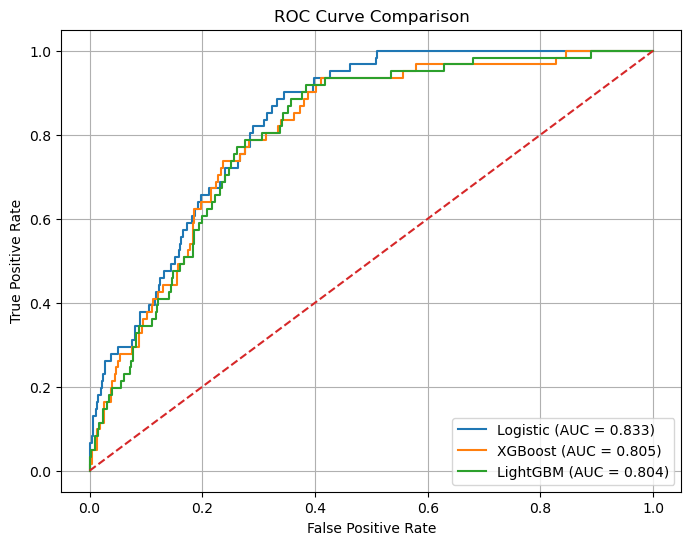

In [54]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# ROC curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_probs)  # logistic
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_probs_xgb)
fpr_lgb, tpr_lgb, _ = roc_curve(y_test, y_probs_lgb)

# AUCs
auc_lr = auc(fpr_lr, tpr_lr)
auc_xgb = auc(fpr_xgb, tpr_xgb)
auc_lgb = auc(fpr_lgb, tpr_lgb)

plt.figure(figsize=(8,6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic (AUC = {auc_lr:.3f})')
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {auc_xgb:.3f})')
plt.plot(fpr_lgb, tpr_lgb, label=f'LightGBM (AUC = {auc_lgb:.3f})')

plt.plot([0,1],[0,1],'--')  # random baseline
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison')
plt.legend()
plt.grid()
plt.show()

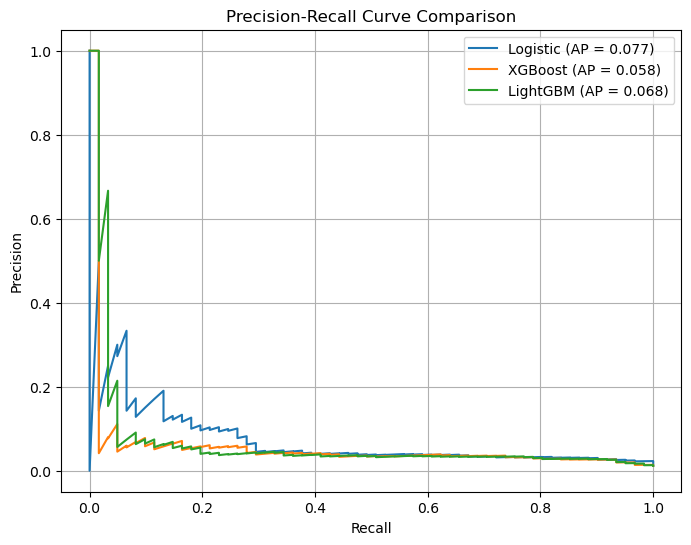

In [55]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Compute PR curves
prec_lr, rec_lr, _ = precision_recall_curve(y_test, y_probs)
prec_xgb, rec_xgb, _ = precision_recall_curve(y_test, y_probs_xgb)
prec_lgb, rec_lgb, _ = precision_recall_curve(y_test, y_probs_lgb)

ap_lr = average_precision_score(y_test, y_probs)
ap_xgb = average_precision_score(y_test, y_probs_xgb)
ap_lgb = average_precision_score(y_test, y_probs_lgb)

plt.figure(figsize=(8,6))
plt.plot(rec_lr, prec_lr, label=f'Logistic (AP = {ap_lr:.3f})')
plt.plot(rec_xgb, prec_xgb, label=f'XGBoost (AP = {ap_xgb:.3f})')
plt.plot(rec_lgb, prec_lgb, label=f'LightGBM (AP = {ap_lgb:.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend()
plt.grid()
plt.show()

In [56]:
from sklearn.metrics import precision_score, recall_score, f1_score

def get_metrics(y_true, y_pred, y_probs):
    return {
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_probs)
    }

metrics = pd.DataFrame([
    get_metrics(y_test, y_pred, y_probs),
    get_metrics(y_test, y_pred_xgb, y_probs_xgb),
    get_metrics(y_test, y_pred_lgb, y_probs_lgb)
], index=["Logistic", "XGBoost", "LightGBM"])

print(metrics)

          Precision    Recall        F1   ROC-AUC
Logistic   0.020239  1.000000  0.039675  0.832802
XGBoost    0.033457  0.442623  0.062212  0.805326
LightGBM   0.035980  0.475410  0.066897  0.803591


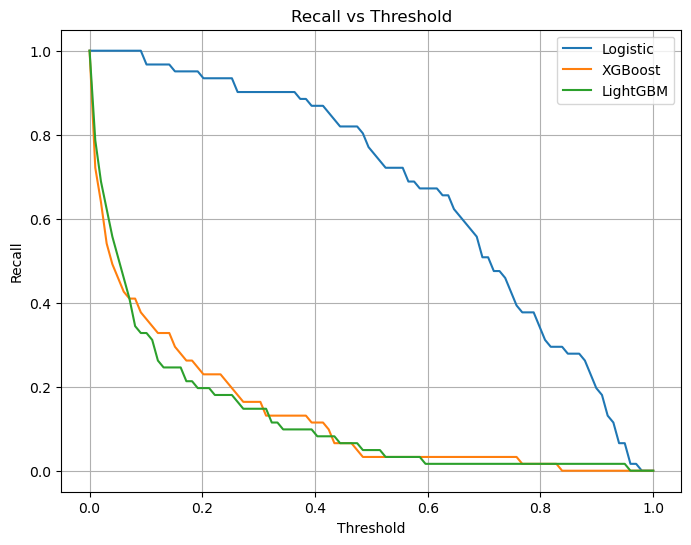

In [47]:
thresholds = np.linspace(0, 1, 100)

recalls_lr = []
recalls_xgb = []
recalls_lgb = []

for t in thresholds:
    recalls_lr.append(recall_score(y_test, (y_probs >= t)))
    recalls_xgb.append(recall_score(y_test, (y_probs_xgb >= t)))
    recalls_lgb.append(recall_score(y_test, (y_probs_lgb >= t)))

plt.figure(figsize=(8,6))
plt.plot(thresholds, recalls_lr, label="Logistic")
plt.plot(thresholds, recalls_xgb, label="XGBoost")
plt.plot(thresholds, recalls_lgb, label="LightGBM")

plt.xlabel("Threshold")
plt.ylabel("Recall")
plt.title("Recall vs Threshold")
plt.legend()
plt.grid()
plt.show()